# Análisis de umbral

### Importación de librerías.

In [1]:
import __main__
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import confusion_matrix, roc_curve, ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt

import sys
sys.path.append('..')
from scripts.modelo_c import ModeloEnsambladoFraude

### Importación de datos.

In [2]:
df = pd.read_csv('../datos/datos_sinteticos.csv', sep=";")
df.head(2)

,cliente_id,fechas_hora,montos,tipos_establecimiento,historico_establecimiento,es_anomalia,tipo_anomalia,promedio,desviacion,maximo,minimo,monto_hora,moda_establecimiento,cantidad_establecimiento
0,1,"['2026-06-08 00:16:00', '2026-06-08 06:14:00',...","['705.29', '628.12', '272.24', '382.26', '1109...","['Farmacia', 'Farmacia', 'Transporte', 'Farmac...","['0.16643057183060853', '0.017594963536259', '...",0,Normal,879.374333,602.582962,2380.04,240.25,34.208766,Farmacia,7
1,2,"['2026-06-14 07:11:00', '2026-06-15 07:48:00',...","['266.04', '518.87', '266.71', '193.6', '264.7...","['Otros', 'Otros', 'Transporte', 'Transporte',...","['0.001894439046728334', '0.01438288653067728'...",0,Normal,346.078000,165.763599,762.78,63.60,16.192467,Otros,5


### Separando las variables predictoras de la objetivo.

In [3]:
X = df.drop(columns = ['es_anomalia'])
y = df['es_anomalia']

### Separación del conjunto de prueba y entrenamiento.

In [4]:
nan_indices = X['tipo_anomalia'].isna()
X_filtered = X[~nan_indices]
y_filtered = y[~nan_indices]

X_train, X_test, y_train, y_test = train_test_split(X_filtered, y_filtered, test_size=0.20, random_state=0, stratify=X_filtered['tipo_anomalia'])

### Costos.

In [5]:
COSTO_FN = 4200
COSTO_FP = 180

## Modelo C

### DataFrame útil para el modelo.

In [6]:
X_train_c =  X_train[['fechas_hora', 'montos', 'tipos_establecimiento', 'historico_establecimiento']]
X_test_c =  X_test[['fechas_hora', 'montos', 'tipos_establecimiento', 'historico_establecimiento']]

### Importación del modelo.

In [7]:
modelo_C = ModeloEnsambladoFraude(umbral=0.50, batch_size=256)

### Predicción de la probabilidad.

In [8]:
y_prob_c = modelo_C.predict(X_train_c)['probabilidad_mayor']

### Métricas respecto a umbrales.

In [9]:
fpr_c, tpr_c, thresholds_c = roc_curve(y_true=y_train, y_score=y_prob_c, drop_intermediate=False)
positivos_c = np.sum(y_train == 1)
negativos_c = np.sum(y_train == 0)

In [10]:
resultados_c = pd.DataFrame({'umbral': thresholds_c.round(6), 'TP': np.rint(tpr_c * positivos_c).astype(int),
                           'FP': np.rint(fpr_c * negativos_c).astype(int)})

resultados_c['FN'] = positivos_c - resultados_c['TP']
resultados_c['TN'] = negativos_c - resultados_c['FP']
resultados_c['costo_total'] = (resultados_c['FN'] * COSTO_FN + resultados_c['FP'] * COSTO_FP)
resultados_c.tail()

,umbral,TP,FP,FN,TN,costo_total
79631,0.015839,8051,71945,0,4,12950100
79632,0.015805,8051,71946,0,3,12950280
79633,0.015131,8051,71947,0,2,12950460
79634,0.014806,8051,71948,0,1,12950640
79635,0.014676,8051,71949,0,0,12950820


### Mejor umbral.

In [11]:
mejor_fila_c = resultados_c.loc[resultados_c["costo_total"].idxmin()]
umbral_optimo_c = mejor_fila_c["umbral"]

print(f"Umbral óptimo: {umbral_optimo_c:.4f}")
print(f"Falsos negativos: {int(mejor_fila_c['FN'])}")
print(f"Falsos positivos: {int(mejor_fila_c['FP'])}")
print(f"Costo mínimo: Q{mejor_fila_c['costo_total']/len(y_train):,.2f}")

Umbral óptimo: 0.4789
Falsos negativos: 78
Falsos positivos: 4346
Costo mínimo: Q13.87


### Gráfico del umbral óptimo.

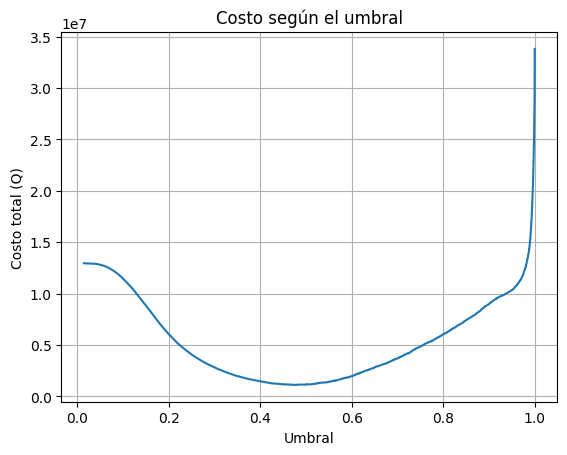

In [12]:
plt.plot(resultados_c["umbral"], resultados_c["costo_total"])
plt.xlabel("Umbral")
plt.ylabel("Costo total (Q)")
plt.title("Costo según el umbral")
plt.grid()
plt.show()

### Matriz de confusión (Conjunto de entrenamiento).

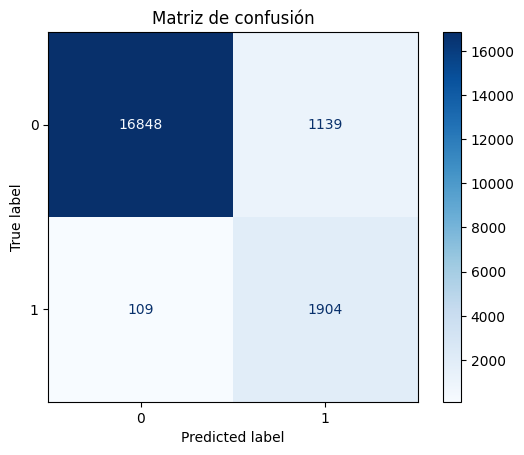

In [13]:
y_prob_test_c = modelo_C.predict(X_test_c)['probabilidad_mayor']
y_pred_optimo_c = (y_prob_test_c >= umbral_optimo_c).astype(int)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_optimo_c, cmap="Blues")
plt.title("Matriz de confusión")
plt.show()